# Fake News Detection Using Natural Language Processing


# Phase 1 – Problem Understanding

## 1. Business Problem

The increasing spread of misleading and fabricated news across digital platforms creates challenges for readers and online communities.

The objective is to develop an NLP-based Machine Learning classification system that identifies whether a news article is Fake or Real.

## 2. Problem Definition

- Learning Type: Supervised Learning
- ML Category: Classification
- Classification Type: Binary Classification
- Domain: Natural Language Processing
- Input Features: News Title and Article Text
- Target Variable: Label
- Output: Fake News / Real News

## 3. Project Objectives

1. Understand and analyze the WELFake dataset.
2. Perform NLP text preprocessing.
3. Extract meaningful numerical features.
4. Train multiple Machine Learning models.
5. Evaluate and optimize model performance.
6. Compare traditional ML and Deep Learning approaches.
7. Deploy the final model using FastAPI and Streamlit.

## 4. Evaluation Metrics

- Accuracy
- Precision
- Recall
- F1-score
- Confusion Matrix
- ROC-AUC

## 5. Expected Outcome

Build an end-to-end Fake News Detection application that classifies news articles using a trained NLP model.

--------------------------------------------------------------------------------------------


# Phase 2 – Data Understanding and Exploratory Data Analysis (EDA)


In [1]:
import numpy as np 
import pandas as pd 

df = pd.read_csv("WELFake_Dataset.csv")
df.head(5)

,Unnamed: 0,title,text,label
0,0,LAW ENFORCEMENT ON HIGH ALERT Following Threat...,No comment is expected from Barack Obama Membe...,1
1,1,NaN,Did they post their votes for Hillary already?,1
2,2,UNBELIEVABLE! OBAMA’S ATTORNEY GENERAL SAYS MO...,"Now, most of the demonstrators gathered last ...",1
3,3,"Bobby Jindal, raised Hindu, uses story of Chri...",A dozen politically active pastors came here f...,0
4,4,SATAN 2: Russia unvelis an image of its terrif...,"The RS-28 Sarmat missile, dubbed Satan 2, will...",1


In [2]:
df.shape

(72134, 4)

In [3]:
df.columns.to_list()

['Unnamed: 0', 'title', 'text', 'label']

In [4]:
df.dtypes


Unnamed: 0    int64
title           str
text            str
label         int64
dtype: object

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 72134 entries, 0 to 72133
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   Unnamed: 0  72134 non-null  int64
 1   title       71576 non-null  str  
 2   text        72095 non-null  str  
 3   label       72134 non-null  int64
dtypes: int64(2), str(2)
memory usage: 235.0 MB


In [6]:
df.describe()

,Unnamed: 0,label
count,72134.000000,72134.000000
mean,36066.500000,0.514404
std,20823.436496,0.499796
min,0.000000,0.000000
25%,18033.250000,0.000000
50%,36066.500000,1.000000
75%,54099.750000,1.000000
max,72133.000000,1.000000


In [7]:
# Detecting duplicates and handling 

# Complete duplicate records
complete_duplicates = df.duplicated().sum()

# Duplicate title and text combinations
article_duplicates = df.duplicated(
    subset=["title", "text"]
).sum()

# Duplicate titles
title_duplicates = df.duplicated(
    subset=["title"]
).sum()

# Duplicate article texts
text_duplicates = df.duplicated(
    subset=["text"]
).sum()

# Check whether identical articles have conflicting labels
label_counts = df.groupby(
    ["title", "text"],
    dropna=False
)["label"].nunique()

conflicting_labels = (label_counts > 1).sum()

# Display results
print("Duplicate Analysis")
print("-" * 40)
print("Complete Duplicates:", complete_duplicates)
print("Duplicate Title-Text Pairs:", article_duplicates)
print("Duplicate Titles:", title_duplicates)
print("Duplicate Article Texts:", text_duplicates)
print("Conflicting Label Groups:", conflicting_labels)


Duplicate Analysis
----------------------------------------
Complete Duplicates: 0
Duplicate Title-Text Pairs: 8456
Duplicate Titles: 9786
Duplicate Article Texts: 9415
Conflicting Label Groups: 0



## Duplicate Handling Strategy

Based on the duplicate analysis, the following strategy will be adopted:

1. Complete duplicate records will be removed if found.
2. Exact duplicate title-text combinations will be identified and reduced to one record.
3. Duplicate headlines will not be removed automatically because different articles can share the same headline.
4. Duplicate article texts will be investigated separately.
5. Conflicting labels will be investigated manually.
6. Missing-value records will be handled separately.
7. Duplicate handling will be completed before train-test splitting to reduce data leakage.

### Conclusion

Exact duplicate article removal will help prevent repeated observations from influencing model training and evaluation.

However, different articles covering the same event will be retained unless there is sufficient evidence that they are duplicate content.


In [8]:
# Target Variable Distribution 

target_counts = df["label"].value_counts().sort_index()

# Display class counts
print("Target Variable Distribution:")
print(target_counts)
print("-" * 20)
# Display category-wise counts
print("\nFake News (0):", target_counts.get(0, 0))
print("Real News (1):", target_counts.get(1, 0))


Target Variable Distribution:
label
0    35028
1    37106
Name: count, dtype: int64
--------------------

Fake News (0): 35028
Real News (1): 37106


  News Category  Count  Percentage
0     Fake News  35028       48.56
1     Real News  37106       51.44


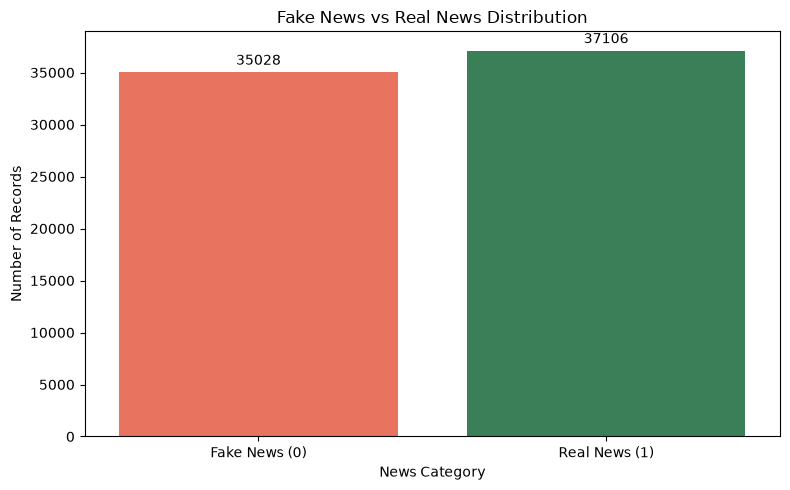

In [9]:

import matplotlib.pyplot as plt
import seaborn as sns

# Calculate class percentages
target_percentage = df["label"].value_counts(normalize=True).sort_index() * 100

# Create summary DataFrame
target_summary = pd.DataFrame({
    "News Category": ["Fake News", "Real News"],
    "Count": target_counts.values,
    "Percentage": target_percentage.values.round(2)
})

print(target_summary)

# Visualize target distribution
plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=df,
    x="label",
    hue="label",
    order=[0, 1],
    palette=["tomato", "seagreen"],
    legend=False
)

plt.title("Fake News vs Real News Distribution")
plt.xlabel("News Category")
plt.ylabel("Number of Records")
plt.xticks([0, 1], ["Fake News (0)", "Real News (1)"])

# Display count labels
for container in ax.containers:
    ax.bar_label(container, fmt="%d", padding=3)

plt.tight_layout()
plt.show()


### Text Length Analysis 


In [10]:
# Calculate Text Length 

# Create a copy for EDA
analysis_df = df.copy()

# Calculate title length
analysis_df["title_char_count"] = analysis_df["title"].str.len()
analysis_df["title_word_count"] = analysis_df["title"].str.split().str.len()

# Calculate article length
analysis_df["text_char_count"] = analysis_df["text"].str.len()
analysis_df["text_word_count"] = analysis_df["text"].str.split().str.len()

# Display sample records
analysis_df[
    ["title_char_count", "title_word_count",
     "text_char_count", "text_word_count", "label"]
].head()


,title_char_count,title_word_count,text_char_count,text_word_count,label
0,130.0,18.0,5049.0,871.0,1
1,NaN,NaN,46.0,8.0,1
2,137.0,18.0,216.0,34.0,1
3,105.0,16.0,8010.0,1321.0,0
4,95.0,16.0,1916.0,329.0,1


In [11]:

# Select text length columns
length_columns = [
    "title_char_count",
    "title_word_count",
    "text_char_count",
    "text_word_count"
]

# Generate statistical summary
length_summary = analysis_df[length_columns].describe().round(2)

print("Text Length Statistical Summary:")
display(length_summary)


Text Length Statistical Summary:


,title_char_count,title_word_count,text_char_count,text_word_count
count,71576.00,71576.00,72095.00,72095.00
mean,77.14,12.27,3270.16,540.84
std,25.03,4.13,3733.11,625.44
min,1.00,1.00,1.00,0.00
25%,62.00,9.00,1379.00,227.00
50%,73.00,12.00,2425.00,399.00
75%,89.00,14.00,4060.00,667.00
max,456.00,72.00,142961.00,24234.00



## Text Length Analysis – Statistical Observations

### Headline Analysis

1. The average headline contains approximately 12 words.
2. The average headline length is 77.14 characters.
3. The median headline word count is 12.
4. The maximum headline length is 72 words.

### Article Analysis

1. The average article contains approximately 541 words.
2. The median article word count is 399.
3. The maximum article length is 24,234 words.
4. The standard deviation of article word count is 625.44.
5. The mean is greater than the median, suggesting a right-skewed distribution.
6. Some articles have unusually large word counts.

### Data Quality Observations

- Some records have missing headlines.
- The minimum article word count is zero, which requires further investigation.
- Extremely long articles may influence statistical analysis and model resource requirements.

### Conclusion

The dataset contains substantial variation in headline and article lengths.

Most articles are considerably longer than their corresponding headlines. The article-length distribution appears right-skewed, with some unusually long records.

Further investigation of extreme values will be required before deciding on text-length limits for NLP models.


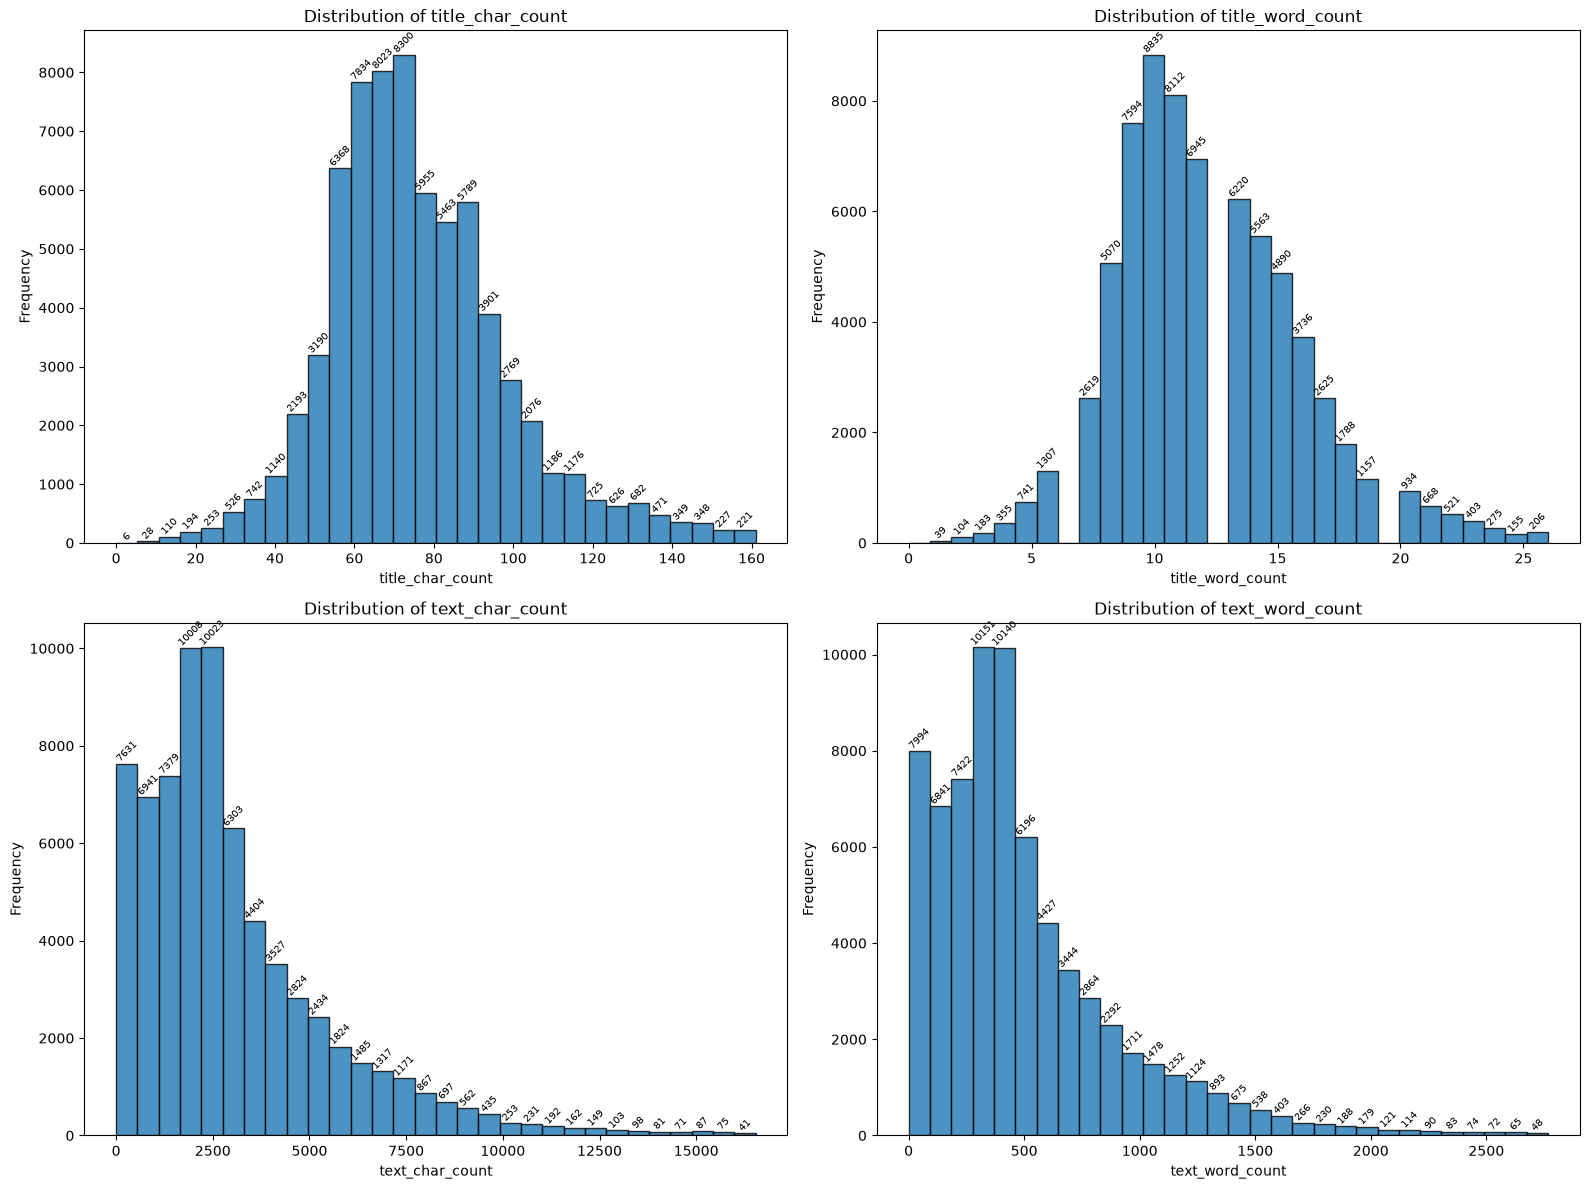

In [12]:

# Define text length columns
length_columns = [
    "title_char_count",
    "title_word_count",
    "text_char_count",
    "text_word_count"
]

# Create 2x2 histogram layout
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

for column, ax in zip(length_columns, axes.flatten()):

    # Limit visualization to 99th percentile
    upper_limit = analysis_df[column].quantile(0.99)

    # Generate histogram
    counts, bins, patches = ax.hist(
        analysis_df[column].dropna(),
        bins=30,
        range=(0, upper_limit),
        edgecolor="black",
        alpha=0.8
    )

    # Display exact frequency values
    for count, patch in zip(counts, patches):
        if count > 0:
            ax.annotate(
                f"{int(count)}",
                (patch.get_x() + patch.get_width() / 2, count),
                ha="center",
                va="bottom",
                fontsize=7,
                rotation=45
            )

    ax.set_title(f"Distribution of {column}")
    ax.set_xlabel(column)
    ax.set_ylabel("Frequency")
    ax.ticklabel_format(axis="y", style="plain")

plt.tight_layout()
plt.show()


In [13]:
# Grouped Statistical Analysis 

# Compare text length statistics by target class

length_comparison = analysis_df.groupby("label")[
    [
        "title_char_count",
        "title_word_count",
        "text_char_count",
        "text_word_count"
    ]
].agg(["mean", "median", "std"]).round(2)

# Rename target labels
length_comparison.index = ["Fake News", "Real News"]

display(length_comparison)


title_char_count               title_word_count               \
                      mean median    std             mean median   std   
Fake News            68.79   67.0  14.38            11.05   11.0  2.85   
Real News            85.14   83.0  29.97            13.44   13.0  4.78   

          text_char_count                  text_word_count                 
                     mean  median      std            mean median     std  
Fake News         3495.32  2642.5  3325.50          577.62  427.0  563.12  
Real News         3057.38  2211.0  4069.67          506.09  369.0  677.28

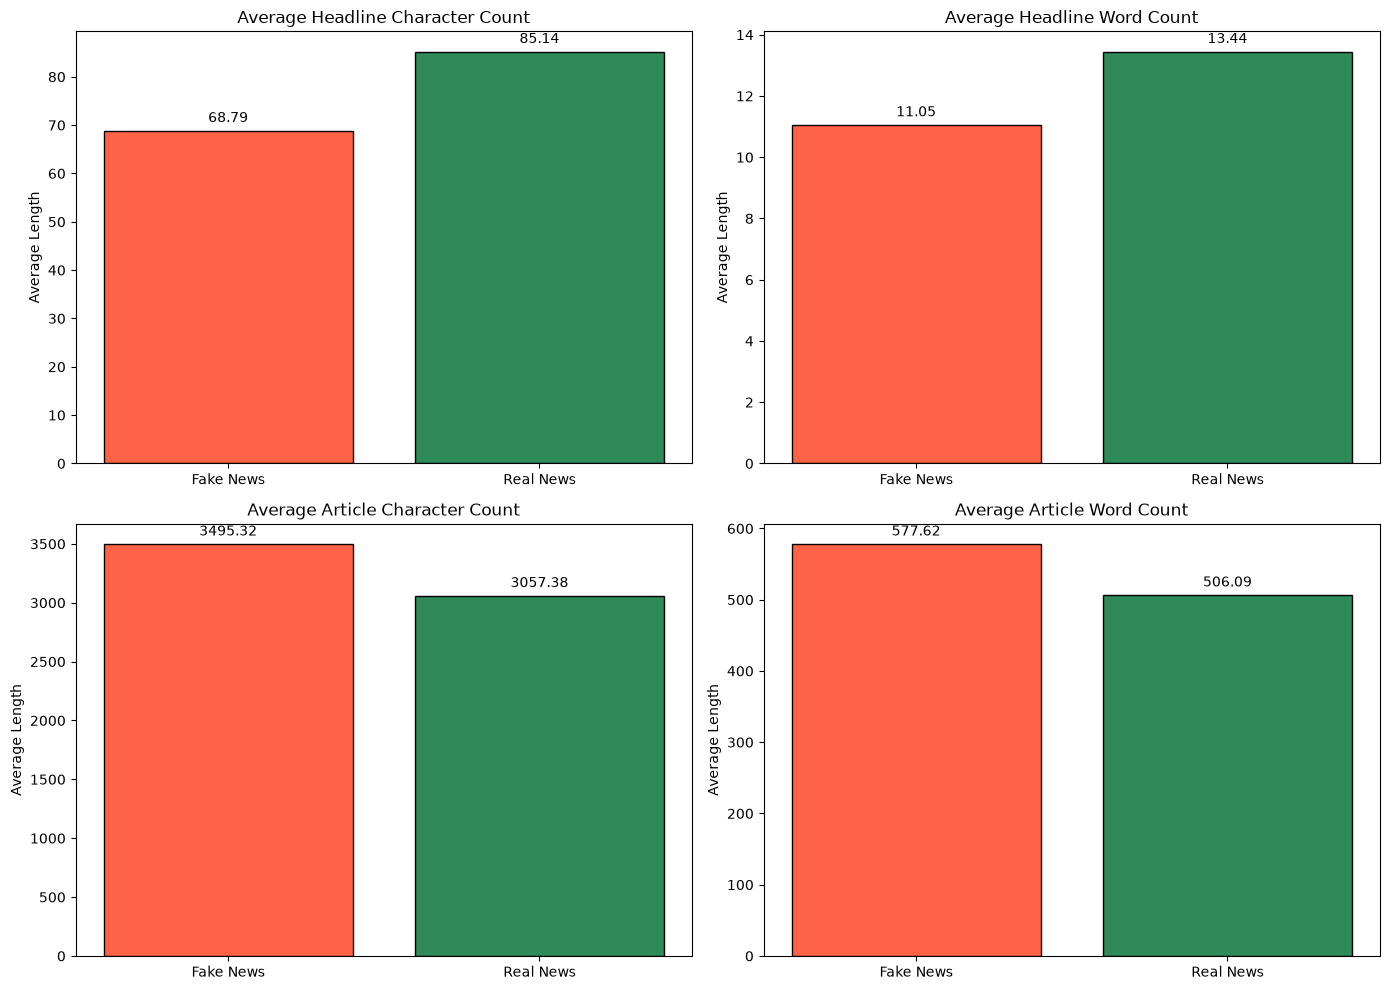

In [14]:

# Calculate average text lengths by news category
length_means = analysis_df.groupby("label")[
    [
        "title_char_count",
        "title_word_count",
        "text_char_count",
        "text_word_count"
    ]
].mean()

# Define chart titles
chart_titles = {
    "title_char_count": "Average Headline Character Count",
    "title_word_count": "Average Headline Word Count",
    "text_char_count": "Average Article Character Count",
    "text_word_count": "Average Article Word Count"
}

# Create 2x2 visualization
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for column, ax in zip(length_means.columns, axes.flatten()):

    values = length_means[column]

    bars = ax.bar(
        ["Fake News", "Real News"],
        values.values,
        color=["tomato", "seagreen"],
        edgecolor="black"
    )

    # Add exact values above bars
    ax.bar_label(
        bars,
        labels=[f"{value:.2f}" for value in values],
        padding=4,
        fontsize=10
    )

    ax.set_title(chart_titles[column])
    ax.set_ylabel("Average Length")

plt.tight_layout()
plt.show()


In [15]:
# Word Frequency Analysis 

# Most Frequent Words Across the Dataset 

from collections import Counter
import re

# Combine all news articles
all_text = " ".join(
    analysis_df["text"].dropna().astype(str)
)

# Convert text to lowercase
all_text = all_text.lower()

# Extract words using regular expressions
all_words = re.findall(r"\b[a-z]+\b", all_text)

# Calculate word frequencies
word_frequency = Counter(all_words)

# Display 20 most frequent words
top_20_words = word_frequency.most_common(20)

print("Top 20 Most Frequent Words:\n")

for word, frequency in top_20_words:
    print(f"{word}: {frequency}")


Top 20 Most Frequent Words:

the: 2242108
to: 1105349
of: 992319
and: 914437
a: 891790
in: 764184
that: 531725
s: 520422
is: 379167
for: 365486
on: 364471
it: 298556
he: 269223
with: 251935
was: 245231
as: 237322
said: 234319
trump: 213565
by: 199506
his: 188945


In [16]:

from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

# Remove stop words and single-character tokens
filtered_words = [
    word for word in all_words
    if word not in ENGLISH_STOP_WORDS and len(word) > 1
]

# Calculate filtered word frequencies
filtered_word_frequency = Counter(filtered_words)

# Display top 20 meaningful words
top_20_filtered = filtered_word_frequency.most_common(20)

print("Top 20 Words After Stop-word Removal:\n")

for word, frequency in top_20_filtered:
    print(f"{word}: {frequency}")


Top 20 Words After Stop-word Removal:

said: 234319
trump: 213565
people: 90445
president: 90282
clinton: 73980
mr: 72389
new: 70862
state: 64211
like: 56562
just: 54676
obama: 51570
states: 50781
government: 50300
time: 49490
year: 45616
house: 44711
donald: 42716
campaign: 42489
united: 42411
news: 40119


In [17]:
# Top 20 Words by News Category 


# Separate Fake News and Real News articles
fake_news_text = " ".join(
    analysis_df.loc[analysis_df["label"] == 0, "text"]
    .dropna()
    .astype(str)
).lower()

real_news_text = " ".join(
    analysis_df.loc[analysis_df["label"] == 1, "text"]
    .dropna()
    .astype(str)
).lower()

# Extract words
fake_words = re.findall(r"\b[a-z]+\b", fake_news_text)
real_words = re.findall(r"\b[a-z]+\b", real_news_text)

# Remove stop words and single-character tokens
fake_words = [
    word for word in fake_words
    if word not in ENGLISH_STOP_WORDS and len(word) > 1
]

real_words = [
    word for word in real_words
    if word not in ENGLISH_STOP_WORDS and len(word) > 1
]

# Calculate word frequencies
fake_frequency = Counter(fake_words)
real_frequency = Counter(real_words)

# Display top 20 words
print("TOP 20 WORDS IN FAKE NEWS")
print("-" * 40)

for word, count in fake_frequency.most_common(20):
    print(f"{word}: {count}")


TOP 20 WORDS IN FAKE NEWS
----------------------------------------
said: 184607
trump: 107201
mr: 66086
president: 51300
new: 42528
people: 41792
state: 38871
states: 31668
government: 30110
reuters: 29342
house: 28578
clinton: 28569
year: 28154
united: 27740
republican: 26548
like: 24796
told: 23991
campaign: 23383
time: 23335
obama: 22955


In [18]:
print("\nTOP 20 WORDS IN REAL NEWS")
print("-" * 40)

for word, count in real_frequency.most_common(20):
    print(f"{word}: {count}")


TOP 20 WORDS IN REAL NEWS
----------------------------------------
trump: 106364
said: 49712
people: 48653
clinton: 45411
president: 38982
just: 34612
like: 31766
hillary: 31592
obama: 28615
new: 28334
time: 26155
state: 25340
donald: 24955
news: 21866
american: 20847
media: 20393
election: 20309
government: 20190
world: 19811
white: 19445


In [19]:
# Normalized Word Frequency Comparison 


# Calculate total words in each category
fake_total_words = len(fake_words)
real_total_words = len(real_words)

print("Total Fake News Words:", fake_total_words)
print("Total Real News Words:", real_total_words)

# Calculate normalized word frequencies per 10,000 words
fake_normalized = {
    word: (count / fake_total_words) * 10000
    for word, count in fake_frequency.items()
}

real_normalized = {
    word: (count / real_total_words) * 10000
    for word, count in real_frequency.items()
}

# Get top 20 words from each category
fake_top_words = fake_frequency.most_common(20)
real_top_words = real_frequency.most_common(20)

# Combine top words from both categories
comparison_words = set(
    [word for word, count in fake_top_words] +
    [word for word, count in real_top_words]
)

# Create comparison DataFrame
word_comparison = pd.DataFrame({
    "Word": list(comparison_words),
    "Fake Frequency": [
        fake_frequency[word] for word in comparison_words
    ],
    "Real Frequency": [
        real_frequency[word] for word in comparison_words
    ],
    "Fake per 10K Words": [
        fake_normalized.get(word, 0) for word in comparison_words
    ],
    "Real per 10K Words": [
        real_normalized.get(word, 0) for word in comparison_words
    ]
})

# Sort by difference in normalized frequency
word_comparison["Difference"] = (
    word_comparison["Fake per 10K Words"] -
    word_comparison["Real per 10K Words"]
)

display(
    word_comparison.sort_values(
        "Difference", ascending=False
    ).round(2)
)


Total Fake News Words: 10542906
Total Real News Words: 9542503


,Word,Fake Frequency,Real Frequency,Fake per 10K Words,Real per 10K Words,Difference
5,said,184607,49712,175.10,52.10,123.01
7,mr,66086,6303,62.68,6.61,56.08
12,reuters,29342,1019,27.83,1.07,26.76
18,republican,26548,12766,25.18,13.38,11.80
11,united,27740,14671,26.31,15.37,10.94
14,new,42528,28334,40.34,29.69,10.65
1,state,38871,25340,36.87,26.55,10.31
24,house,28578,16133,27.11,16.91,10.20
19,states,31668,19113,30.04,20.03,10.01
9,year,28154,17462,26.70,18.30,8.41


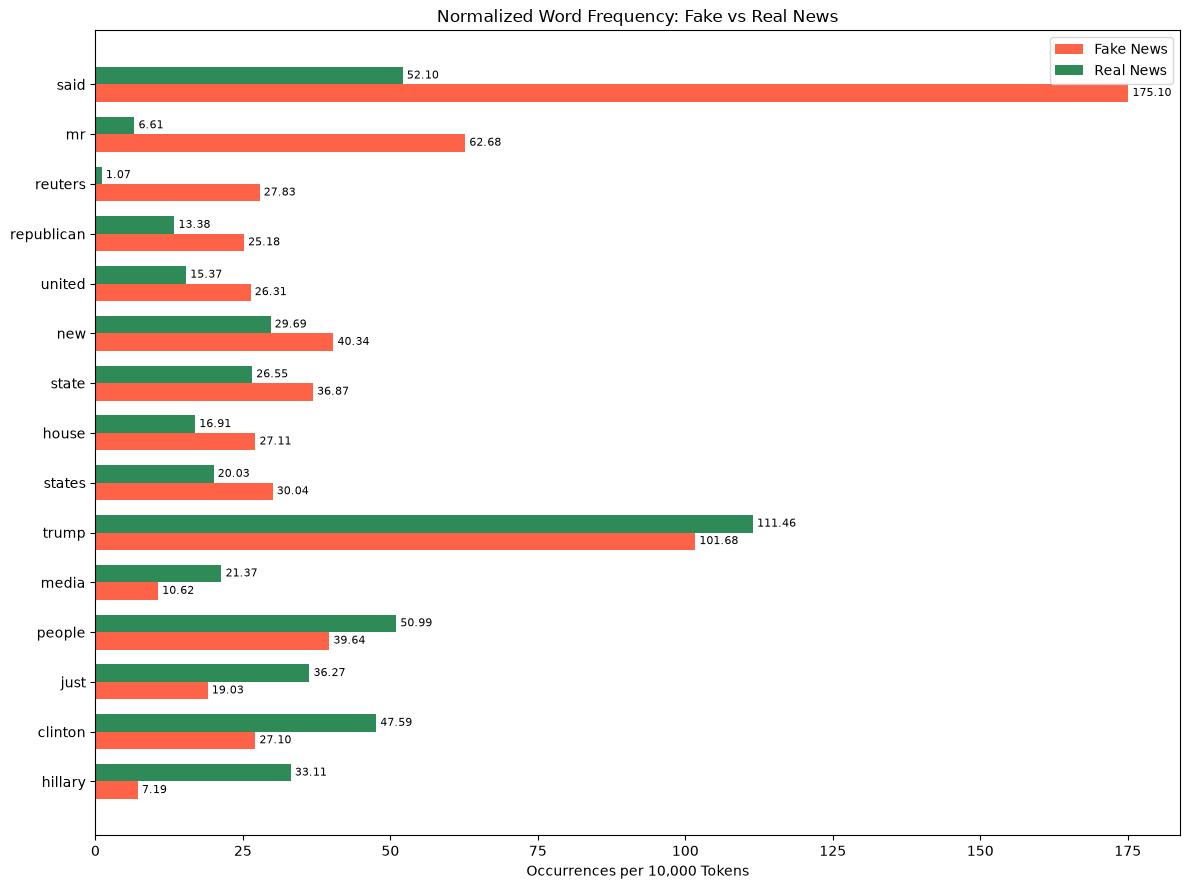

In [20]:
# Fake vs Real Word Frequency 


# Select top 15 words by absolute normalized frequency difference
top_comparison = (
    word_comparison
    .assign(
        Abs_Difference=lambda x: x["Difference"].abs()
    )
    .nlargest(15, "Abs_Difference")
    .sort_values("Difference")
)

# Create horizontal grouped bar chart
fig, ax = plt.subplots(figsize=(12, 9))

y = np.arange(len(top_comparison))
height = 0.35

fake_bars = ax.barh(
    y - height / 2,
    top_comparison["Fake per 10K Words"],
    height,
    label="Fake News",
    color="tomato"
)

real_bars = ax.barh(
    y + height / 2,
    top_comparison["Real per 10K Words"],
    height,
    label="Real News",
    color="seagreen"
)

# Add exact values to bars
ax.bar_label(fake_bars, fmt="%.2f", padding=3, fontsize=8)
ax.bar_label(real_bars, fmt="%.2f", padding=3, fontsize=8)

ax.set_yticks(y)
ax.set_yticklabels(top_comparison["Word"])
ax.set_xlabel("Occurrences per 10,000 Tokens")
ax.set_title("Normalized Word Frequency: Fake vs Real News")
ax.legend()

plt.tight_layout()
plt.show()


In [21]:
# Bigram Analysis (Two-word combinations)

from collections import Counter
import re
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

# Combine article text separately for each class
fake_news_text = " ".join(
    analysis_df.loc[analysis_df["label"] == 0, "text"].dropna().astype(str)
).lower()

real_news_text = " ".join(
    analysis_df.loc[analysis_df["label"] == 1, "text"].dropna().astype(str)
).lower()

# Tokenize text
fake_tokens = re.findall(r"\b[a-z]{2,}\b", fake_news_text)
real_tokens = re.findall(r"\b[a-z]{2,}\b", real_news_text)

# Generate consecutive bigrams and remove those containing stopwords
fake_bigrams = [
    (w1, w2)
    for w1, w2 in zip(fake_tokens, fake_tokens[1:])
    if w1 not in ENGLISH_STOP_WORDS and w2 not in ENGLISH_STOP_WORDS
]

real_bigrams = [
    (w1, w2)
    for w1, w2 in zip(real_tokens, real_tokens[1:])
    if w1 not in ENGLISH_STOP_WORDS and w2 not in ENGLISH_STOP_WORDS
]

# Count bigrams
fake_bigram_frequency = Counter(fake_bigrams)
real_bigram_frequency = Counter(real_bigrams)

# Display top 20 bigrams
print("Top 20 Bigrams - Fake News:")
for bigram, count in fake_bigram_frequency.most_common(20):
    print(" ".join(bigram), ":", count)

print("\nTop 20 Bigrams - Real News:")
for bigram, count in real_bigram_frequency.most_common(20):
    print(" ".join(bigram), ":", count)

Top 20 Bigrams - Fake News:
united states : 22262
mr trump : 17557
donald trump : 16894
white house : 14005
new york : 12837
president donald : 7102
washington reuters : 6674
north korea : 6666
islamic state : 6279
hillary clinton : 6193
prime minister : 5678
trump said : 4875
barack obama : 4865
supreme court : 4491
mrs clinton : 4165
national security : 3970
told reporters : 3867
president barack : 3801
trump administration : 3774
told reuters : 3531

Top 20 Bigrams - Real News:
donald trump : 23086
hillary clinton : 16539
united states : 12079
white house : 9645
featured image : 7927
twitter com : 7465
new york : 7126
pic twitter : 6931
president obama : 5136
getty images : 4167
fox news : 4156
president trump : 4149
year old : 3997
barack obama : 3544
american people : 2808
law enforcement : 2787
clinton campaign : 2744
obama administration : 2726
national security : 2705
state department : 2596


In [23]:
from collections import Counter
import re
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

def get_bigram_frequency(data):
    bigram_frequency = Counter()

    for article in data.dropna().astype(str):
        tokens = re.findall(r"\b[a-z]{2,}\b", article.lower())

        article_bigrams = [
            (w1, w2)
            for w1, w2 in zip(tokens, tokens[1:])
            if w1 not in ENGLISH_STOP_WORDS
            and w2 not in ENGLISH_STOP_WORDS
        ]

        bigram_frequency.update(article_bigrams)

    return bigram_frequency


# Calculate bigram frequencies separately for each class
fake_bigram_frequency = get_bigram_frequency(
    analysis_df.loc[analysis_df["label"] == 0, "text"]
)

real_bigram_frequency = get_bigram_frequency(
    analysis_df.loc[analysis_df["label"] == 1, "text"]
)


# Display top 20 bigrams without truncation
fake_top_20 = pd.DataFrame(
    [
        (" ".join(bigram), count)
        for bigram, count in fake_bigram_frequency.most_common(20)
    ],
    columns=["Bigram", "Frequency"]
)

real_top_20 = pd.DataFrame(
    [
        (" ".join(bigram), count)
        for bigram, count in real_bigram_frequency.most_common(20)
    ],
    columns=["Bigram", "Frequency"]
)

print("TOP 20 BIGRAMS - FAKE NEWS")
print(fake_top_20.to_string(index=False))

TOP 20 BIGRAMS - FAKE NEWS
              Bigram  Frequency
       united states      22262
            mr trump      17557
        donald trump      16894
         white house      14005
            new york      12837
    president donald       7102
  washington reuters       6674
         north korea       6666
       islamic state       6279
     hillary clinton       6193
      prime minister       5678
          trump said       4875
        barack obama       4865
       supreme court       4491
         mrs clinton       4165
   national security       3970
      told reporters       3867
    president barack       3801
trump administration       3774
        told reuters       3531


In [24]:
print("TOP 20 BIGRAMS - REAL NEWS (1 to 20)")
print(real_top_20.iloc[:20].to_string(index=False))

TOP 20 BIGRAMS - REAL NEWS (1 to 20)
              Bigram  Frequency
        donald trump      23086
     hillary clinton      16539
       united states      12079
         white house       9645
      featured image       7927
         twitter com       7465
            new york       7126
         pic twitter       6931
     president obama       5136
        getty images       4167
            fox news       4156
     president trump       4149
            year old       3997
        barack obama       3544
     american people       2808
     law enforcement       2787
    clinton campaign       2744
obama administration       2726
   national security       2705
    state department       2596


In [ ]:
# Extract top 20 trigrams 

from collections import Counter
import re
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

def get_trigram_frequency(data):
    trigram_frequency = Counter()

    for article in data.dropna().astype(str):
        tokens = re.findall(r"\b[a-z]{2,}\b", article.lower())

        article_trigrams = [
            (w1, w2, w3)
            for w1, w2, w3 in zip(tokens, tokens[1:], tokens[2:])
            if w1 not in ENGLISH_STOP_WORDS
            and w2 not in ENGLISH_STOP_WORDS
            and w3 not in ENGLISH_STOP_WORDS
        ]

        trigram_frequency.update(article_trigrams)

    return trigram_frequency


# Calculate trigrams separately for each class
fake_trigram_frequency = get_trigram_frequency(
    analysis_df.loc[analysis_df["label"] == 0, "text"]
)

real_trigram_frequency = get_trigram_frequency(
    analysis_df.loc[analysis_df["label"] == 1, "text"]
)

# Display top 20 trigrams
fake_top_20_trigrams = pd.DataFrame(
    [
        (" ".join(phrase), count)
        for phrase, count in fake_trigram_frequency.most_common(20)
    ],
    columns=["Trigram", "Frequency"]
)

real_top_20_trigrams = pd.DataFrame(
    [
        (" ".join(phrase), count)
        for phrase, count in real_trigram_frequency.most_common(20)
    ],
    columns=["Trigram", "Frequency"]
)

print("TOP 20 TRIGRAMS - FAKE NEWS")
print(fake_top_20_trigrams.to_string(index=False))

TOP 20 TRIGRAMS - FAKE NEWS
                     Trigram  Frequency
      president donald trump       7035
      president barack obama       3800
              new york times       2871
    reuters president donald       1523
washington reuters president       1496
               new york city       1293
         affordable care act       1171
    president vladimir putin       1130
   national security adviser       1010
            white house said        981
           speaker paul ryan        977
       president george bush        907
               mr trump said        867
          elect donald trump        849
            new york reuters        845
      president elect donald        839
         state rex tillerson        776
      leader mitch mcconnell        770
  russian president vladimir        741
    chancellor angela merkel        709

TOP 20 TRIGRAMS - REAL NEWS
                      Trigram  Frequency
              pic twitter com       6931
               new yo

In [26]:
print("\nTOP 20 TRIGRAMS - REAL NEWS")
print(real_top_20_trigrams.to_string(index=False))


TOP 20 TRIGRAMS - REAL NEWS
                      Trigram  Frequency
              pic twitter com       6931
               new york times       2586
 donald trump realdonaldtrump       1731
           black lives matter       1597
       president barack obama       1266
         director james comey       1084
       president donald trump       1081
           fbi director james       1025
                new york city        918
            century wire says        746
         video screen capture        733
              www youtube com        725
            https www youtube        672
          wall street journal        662
            youtube com watch        658
democratic national committee        593
         nominee donald trump        570
           make america great        563
     hillary clinton campaign        554
          affordable care act        546


In [27]:
# Title vs Article Text Analysis 

# Calculate average title and article lengths by target class

title_article_comparison = analysis_df.groupby("label").agg(
    Average_Title_Words=("title_word_count", "mean"),
    Average_Article_Words=("text_word_count", "mean"),
    Median_Title_Words=("title_word_count", "median"),
    Median_Article_Words=("text_word_count", "median")
).round(2)

print(title_article_comparison)

       Average_Title_Words  Average_Article_Words  Median_Title_Words  \
label                                                                   
0                    11.05                 577.62                11.0   
1                    13.44                 506.09                13.0   

       Median_Article_Words  
label                        
0                     427.0  
1                     369.0  


In [28]:
# EDA conclusion 

print("========== FINAL EDA SUMMARY ==========")

print("\n1. Dataset Shape:")
print(analysis_df.shape)

print("\n2. Missing Values:")
print(analysis_df.isnull().sum())

print("\n3. Duplicate Title-Text Combinations:")
print(analysis_df.duplicated(subset=["title", "text"]).sum())

print("\n4. Target Distribution:")
print(analysis_df["label"].value_counts())

print("\n5. Average Text Length by Class:")
print(
    analysis_df.groupby("label")[
        ["title_word_count", "text_word_count"]
    ].mean().round(2)
)

print("\n========== EDA COMPLETED ==========")

========== FINAL EDA SUMMARY ==========

1. Dataset Shape:
(72134, 8)

2. Missing Values:
Unnamed: 0            0
title               558
text                 39
label                 0
title_char_count    558
title_word_count    558
text_char_count      39
text_word_count      39
dtype: int64

3. Duplicate Title-Text Combinations:
8456

4. Target Distribution:
label
1    37106
0    35028
Name: count, dtype: int64

5. Average Text Length by Class:
       title_word_count  text_word_count
label                                   
0                 11.05           577.62
1                 13.44           506.09

========== EDA COMPLETED ==========


## Phase 3 – Data Cleaning and Preparation

In [29]:
# Data Cleaning and Preparation 

# Create a working copy
clean_df = df.copy()

# Remove unnecessary index column
clean_df.drop(columns=["Unnamed: 0"], inplace=True)

print("Dataset Shape:", clean_df.shape)
print("\nColumn Names:", clean_df.columns.tolist())
print("\nMissing Values:\n", clean_df.isnull().sum())

Dataset Shape: (72134, 3)

Column Names: ['title', 'text', 'label']

Missing Values:
 title    558
text      39
label      0
dtype: int64


In [30]:
# Handle missing values 

# Fill missing titles and article texts with empty strings
clean_df["title"] = clean_df["title"].fillna("")
clean_df["text"] = clean_df["text"].fillna("")

# Remove records where both title and text are empty or whitespace
clean_df = clean_df[
    (clean_df["title"].str.strip() != "") |
    (clean_df["text"].str.strip() != "")
].copy()

print("Shape after handling missing values:", clean_df.shape)
print("\nMissing Values:\n", clean_df.isnull().sum())

Shape after handling missing values: (72134, 3)

Missing Values:
 title    0
text     0
label    0
dtype: int64


In [31]:
# Validate target and data quality 

print("Target Distribution:")
print(clean_df["label"].value_counts())

print("\nMissing Values:")
print(clean_df.isnull().sum())

print("\nEmpty Titles:", (clean_df["title"].str.strip() == "").sum())
print("Empty Articles:", (clean_df["text"].str.strip() == "").sum())

print("\nDuplicate Title-Text Pairs:",
      clean_df.duplicated(subset=["title", "text"]).sum())

Target Distribution:
label
1    37106
0    35028
Name: count, dtype: int64

Missing Values:
title    0
text     0
label    0
dtype: int64

Empty Titles: 558
Empty Articles: 783

Duplicate Title-Text Pairs: 8456


In [32]:
# Remove duplicates 

# Remove exact duplicate title-text combinations
before = len(clean_df)

clean_df.drop_duplicates(
    subset=["title", "text"],
    keep="first",
    inplace=True
)

print("Records Before:", before)
print("Records After:", len(clean_df))
print("Duplicates Removed:", before - len(clean_df))

Records Before: 72134
Records After: 63678
Duplicates Removed: 8456


In [33]:
# Final validation 

print("Final Dataset Shape:", clean_df.shape)

print("\nMissing Values:")
print(clean_df.isnull().sum())

print("\nRemaining Duplicate Records:",
      clean_df.duplicated(subset=["title", "text"]).sum())

print("\nTarget Distribution:")
print(clean_df["label"].value_counts())

Final Dataset Shape: (63678, 3)

Missing Values:
title    0
text     0
label    0
dtype: int64

Remaining Duplicate Records: 0

Target Distribution:
label
0    34791
1    28887
Name: count, dtype: int64


In [34]:
# Save the cleaned dataset 

# Save cleaned dataset
clean_df.to_csv("WELFake_Cleaned.csv", index=False)

print("Cleaned dataset saved successfully!")
print("Final Shape:", clean_df.shape)

Cleaned dataset saved successfully!
Final Shape: (63678, 3)


## Phase 4 – NLP Text Preprocessing

In [35]:
# Combine title and article text
clean_df["combined_text"] = (
    clean_df["title"].fillna("") + " " +
    clean_df["text"].fillna("")
).str.strip()

# Inspect the results
print("Dataset Shape:", clean_df.shape)

print("\nCombined Text Examples:")
for i in range(3):
    print(f"\nRecord {i + 1}:")
    print(clean_df["combined_text"].iloc[i][:500])


Dataset Shape: (63678, 4)

Combined Text Examples:

Record 1:
LAW ENFORCEMENT ON HIGH ALERT Following Threats Against Cops And Whites On 9-11By #BlackLivesMatter And #FYF911 Terrorists [VIDEO] No comment is expected from Barack Obama Members of the #FYF911 or #FukYoFlag and #BlackLivesMatter movements called for the lynching and hanging of white people and cops. They encouraged others on a radio show Tuesday night to  turn the tide  and kill white people and cops to send a message about the killing of black people in America.One of the F***YoFlag organizer

Record 2:
Did they post their votes for Hillary already?

Record 3:
UNBELIEVABLE! OBAMA’S ATTORNEY GENERAL SAYS MOST CHARLOTTE RIOTERS WERE “PEACEFUL” PROTESTERS…In Her Home State Of North Carolina [VIDEO]  Now, most of the demonstrators gathered last night were exercising their constitutional and protected right to peaceful protest in order to raise issues and create change.    Loretta Lynch aka Eric Holder in a skirt


In [36]:
# Basic text cleaning 

import re

def preprocess_text(text):
    text = text.lower()

    # Remove URLs
    text = re.sub(r"http\S+|www\S+", "", text)

    # Remove HTML tags
    text = re.sub(r"<.*?>", "", text)

    # Remove special characters and punctuation
    text = re.sub(r"[^a-z0-9\s]", " ", text)

    # Remove extra whitespace
    text = re.sub(r"\s+", " ", text).strip()

    return text


# Apply preprocessing
clean_df["clean_text"] = clean_df["combined_text"].apply(preprocess_text)

# Inspect results
print("Original Text:\n")
print(clean_df["combined_text"].iloc[0][:500])

print("\nPreprocessed Text:\n")
print(clean_df["clean_text"].iloc[0][:500])

print("\nDataset Shape:", clean_df.shape)

Original Text:

LAW ENFORCEMENT ON HIGH ALERT Following Threats Against Cops And Whites On 9-11By #BlackLivesMatter And #FYF911 Terrorists [VIDEO] No comment is expected from Barack Obama Members of the #FYF911 or #FukYoFlag and #BlackLivesMatter movements called for the lynching and hanging of white people and cops. They encouraged others on a radio show Tuesday night to  turn the tide  and kill white people and cops to send a message about the killing of black people in America.One of the F***YoFlag organizer

Preprocessed Text:

law enforcement on high alert following threats against cops and whites on 9 11by blacklivesmatter and fyf911 terrorists video no comment is expected from barack obama members of the fyf911 or fukyoflag and blacklivesmatter movements called for the lynching and hanging of white people and cops they encouraged others on a radio show tuesday night to turn the tide and kill white people and cops to send a message about the killing of black people in america one

In [37]:
# Preprocessing Quality Check.

# Check empty preprocessed records
empty_text_count = (clean_df["clean_text"].str.strip() == "").sum()

# Compare original and cleaned text lengths
original_avg = clean_df["combined_text"].str.len().mean()
cleaned_avg = clean_df["clean_text"].str.len().mean()

print("Empty Preprocessed Records:", empty_text_count)

print("Average Original Length:", round(original_avg, 2))
print("Average Cleaned Length:", round(cleaned_avg, 2))

print("\nPreprocessed Text Examples:")
print(clean_df["clean_text"].head(3).to_string(index=False))

Empty Preprocessed Records: 18
Average Original Length: 3351.56
Average Cleaned Length: 3240.82

Preprocessed Text Examples:
law enforcement on high alert following threats...
     did they post their votes for hillary already
unbelievable obama s attorney general says most...


In [38]:
# Remove records with empty preprocessed text
clean_df = clean_df[
    clean_df["clean_text"].str.strip() != ""
].copy()

print("Final Dataset Shape:", clean_df.shape)
print("Empty Text Records:",
      (clean_df["clean_text"].str.strip() == "").sum())

Final Dataset Shape: (63660, 5)
Empty Text Records: 0


In [39]:
clean_df.to_csv("WELFake_Preprocessed.csv", index=False)

print("Preprocessed dataset saved successfully!")

Preprocessed dataset saved successfully!


## Phase 5 – Feature Extraction

In [40]:
# Define input features and target
X = clean_df["clean_text"]
y = clean_df["label"]

print("Input Features Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nTarget Distribution:")
print(y.value_counts())

Input Features Shape: (63660,)
Target Shape: (63660,)

Target Distribution:
label
0    34791
1    28869
Name: count, dtype: int64


In [41]:
# Train-Test Split 

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Samples:", len(X_train))
print("Testing Samples:", len(X_test))

print("\nTraining Target Distribution:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting Target Distribution:")
print(y_test.value_counts(normalize=True).round(3))

Training Samples: 50928
Testing Samples: 12732

Training Target Distribution:
label
0    0.547
1    0.453
Name: proportion, dtype: float64

Testing Target Distribution:
label
0    0.546
1    0.454
Name: proportion, dtype: float64


In [42]:
# TF-IDF Vectorization 

from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    max_features=50000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    sublinear_tf=True
)

# Fit only on training data
X_train_tfidf = tfidf.fit_transform(X_train)

# Transform test data using training vocabulary
X_test_tfidf = tfidf.transform(X_test)

print("Training TF-IDF Shape:", X_train_tfidf.shape)
print("Testing TF-IDF Shape:", X_test_tfidf.shape)
print("Vocabulary Size:", len(tfidf.vocabulary_))

Training TF-IDF Shape: (50928, 50000)
Testing TF-IDF Shape: (12732, 50000)
Vocabulary Size: 50000


In [43]:
# Inspect one training document
feature_names = tfidf.get_feature_names_out()

sample_vector = X_train_tfidf[0]

# Get non-zero feature indices and values
nonzero_indices = sample_vector.nonzero()[1]
feature_values = sample_vector.data

# Display top 15 features
top_indices = feature_values.argsort()[-15:][::-1]

print("Original Text:\n")
print(X_train.iloc[0][:500])

print("\nTop 15 TF-IDF Features:\n")

for index in top_indices:
    feature_index = nonzero_indices[index]
    print(
        feature_names[feature_index],
        ":", round(feature_values[index], 4)
    )

Original Text:

china and russia chase us destroyer away after trump s navy creeps up on north korea trump s loyalty to vladimir putin is being tested like never before on one hand the donald really wants a war with north korea on the other both russia and china have told him to back the f ck off and the associated press reports that these warnings are becoming more forceful after trump s navy sent a destroyer into the korean peninsula china and russia have dispatched intelligence gathering vessels from their n

Top 15 TF-IDF Features:

korean peninsula : 0.1307
destroyer : 0.1263
the korean : 0.1259
peninsula : 0.1163
and china : 0.1123
china : 0.1096
vessels : 0.1092
north korea : 0.1059
china and : 0.1053
and russia : 0.1031
korean : 0.1024
chase : 0.1024
korea : 0.1014
with north : 0.0984
that both : 0.0978


## Phase 6 – Model Development

### Step 6.1: Logistic Regression

In [44]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Initialize model
lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train the model
lr_model.fit(X_train_tfidf, y_train)

# Predict test data
y_pred_lr = lr_model.predict(X_test_tfidf)

# Evaluate model
print("LOGISTIC REGRESSION RESULTS")
print("-" * 40)

print("Accuracy :", round(accuracy_score(y_test, y_pred_lr), 4))
print("Precision:", round(precision_score(y_test, y_pred_lr, average="binary"), 4))
print("Recall   :", round(recall_score(y_test, y_pred_lr, average="binary"), 4))
print("F1 Score :", round(f1_score(y_test, y_pred_lr, average="binary"), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_lr))

LOGISTIC REGRESSION RESULTS
----------------------------------------
Accuracy : 0.9598
Precision: 0.9544
Recall   : 0.957
F1 Score : 0.9557

Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.96      0.96      6958
           1       0.95      0.96      0.96      5774

    accuracy                           0.96     12732
   macro avg       0.96      0.96      0.96     12732
weighted avg       0.96      0.96      0.96     12732

Confusion Matrix:
[[6694  264]
 [ 248 5526]]


### Model 1 - Logistic Regression – Model Evaluation

- Accuracy: 95.98%
- Precision: 95.44% (Real News)
- Recall: 95.70% (Real News)
- F1-score: 95.57% (Real News)

**Confusion Matrix:**
- True Negative: 6,694
- False Positive: 264
- False Negative: 248
- True Positive: 5,526

**Conclusion:**

Logistic Regression achieved 95.98% accuracy on the test dataset.
The model demonstrated balanced precision, recall and F1-scores
across both classes.

It provides a strong baseline for our Fake News Detection project.
Further comparison with other NLP classification algorithms is
required before selecting the final model.

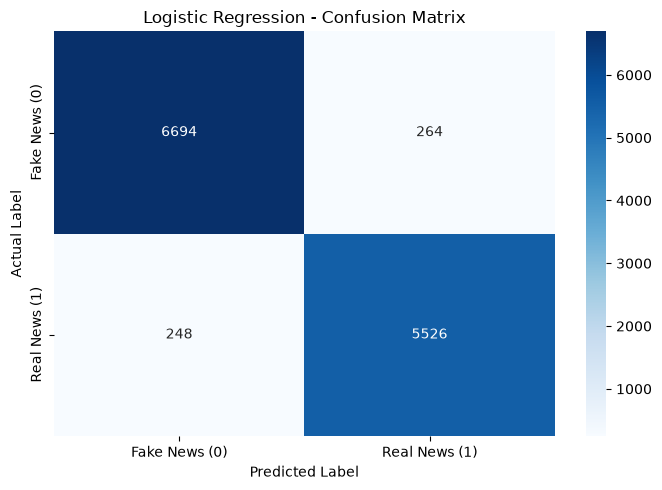

In [45]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Generate confusion matrix
cm = confusion_matrix(y_test, y_pred_lr)

# Plot heatmap
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Fake News (0)", "Real News (1)"],
    yticklabels=["Fake News (0)", "Real News (1)"]
)

plt.title("Logistic Regression - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

### Model 2 - Multinomial Naive Bayes

In [46]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Initialize model
nb_model = MultinomialNB(alpha=1.0)

# Train model
nb_model.fit(X_train_tfidf, y_train)

# Make predictions
y_pred_nb = nb_model.predict(X_test_tfidf)

# Evaluate model
print("MULTINOMIAL NAIVE BAYES RESULTS")
print("-" * 40)

print("Accuracy :", round(accuracy_score(y_test, y_pred_nb), 4))
print("Precision:", round(precision_score(y_test, y_pred_nb), 4))
print("Recall   :", round(recall_score(y_test, y_pred_nb), 4))
print("F1 Score :", round(f1_score(y_test, y_pred_nb), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_nb))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_nb))

MULTINOMIAL NAIVE BAYES RESULTS
----------------------------------------
Accuracy : 0.8698
Precision: 0.8386
Recall   : 0.8828
F1 Score : 0.8601

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.86      0.88      6958
           1       0.84      0.88      0.86      5774

    accuracy                           0.87     12732
   macro avg       0.87      0.87      0.87     12732
weighted avg       0.87      0.87      0.87     12732

Confusion Matrix:
[[5977  981]
 [ 677 5097]]


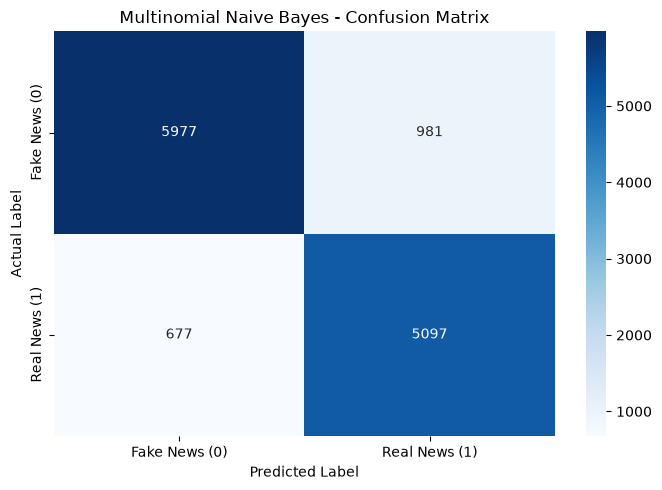

In [47]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm_nb = confusion_matrix(y_test, y_pred_nb)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_nb,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Fake News (0)", "Real News (1)"],
    yticklabels=["Fake News (0)", "Real News (1)"]
)

plt.title("Multinomial Naive Bayes - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

### Multinomial Naive Bayes – Model Evaluation

- Accuracy: 86.98%
- Precision: 83.86% (Real News)
- Recall: 88.28% (Real News)
- F1-score: 86.01% (Real News)

**Confusion Matrix:**
- True Negative: 5,977
- False Positive: 981
- False Negative: 677
- True Positive: 5,097

**Conclusion:**

Multinomial Naive Bayes achieved 86.98% accuracy.
It provides a useful NLP classification benchmark but
performed below Logistic Regression on the current test set.

Logistic Regression remains our leading model.

### Model 3 - Linear SVM

In [48]:
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)

# Initialize model
svm_model = LinearSVC(
    C=1.0,
    random_state=42,
    max_iter=2000
)

# Train
svm_model.fit(X_train_tfidf, y_train)

# Predict
y_pred_svm = svm_model.predict(X_test_tfidf)

# Evaluate
print("LINEAR SVM RESULTS")
print("-" * 40)

print("Accuracy :", round(accuracy_score(y_test, y_pred_svm), 4))
print("Precision:", round(precision_score(y_test, y_pred_svm), 4))
print("Recall   :", round(recall_score(y_test, y_pred_svm), 4))
print("F1 Score :", round(f1_score(y_test, y_pred_svm), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_svm))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_svm))

LINEAR SVM RESULTS
----------------------------------------
Accuracy : 0.9717
Precision: 0.9674
Recall   : 0.9704
F1 Score : 0.9689

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.97      0.97      6958
           1       0.97      0.97      0.97      5774

    accuracy                           0.97     12732
   macro avg       0.97      0.97      0.97     12732
weighted avg       0.97      0.97      0.97     12732

Confusion Matrix:
[[6769  189]
 [ 171 5603]]


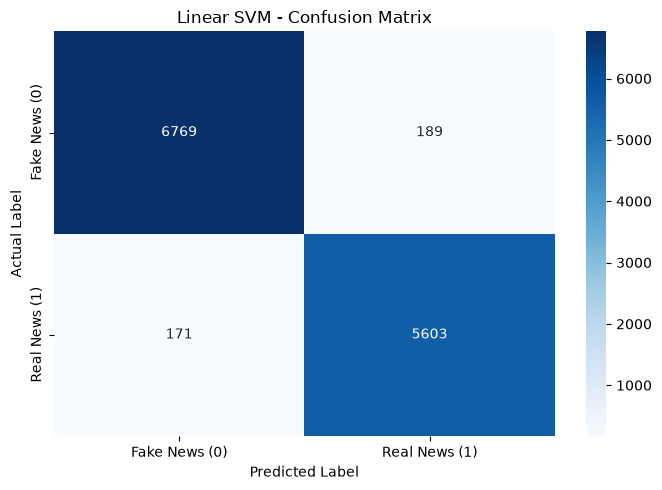

In [49]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm_svm = confusion_matrix(y_test, y_pred_svm)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_svm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Fake News (0)", "Real News (1)"],
    yticklabels=["Fake News (0)", "Real News (1)"]
)

plt.title("Linear SVM - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

### Linear SVM – Model Evaluation

- Accuracy: 97.17%
- Precision: 96.74% (Real News)
- Recall: 97.04% (Real News)
- F1-score: 96.89% (Real News)

**Confusion Matrix:**
- True Negative: 6,769
- False Positive: 189
- False Negative: 171
- True Positive: 5,603

**Conclusion:**

Linear SVM achieved 97.17% accuracy and
96.89% F1-score on the test dataset.

It outperformed Logistic Regression and
Multinomial Naive Bayes across the evaluated metrics.

Linear SVM is currently the leading candidate
for our Fake News Detection project.

### Model 4 - Random Forest Classifier

In [50]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Initialize Random Forest
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=30,
    min_samples_split=5,
    min_samples_leaf=2,
    max_features="sqrt",
    random_state=42,
    n_jobs=-1
)

# Train model
rf_model.fit(X_train_tfidf, y_train)

# Predictions
y_pred_rf = rf_model.predict(X_test_tfidf)

# Evaluation
print("RANDOM FOREST RESULTS")
print("-" * 40)

print("Accuracy :", round(accuracy_score(y_test, y_pred_rf), 4))
print("Precision:", round(precision_score(y_test, y_pred_rf), 4))
print("Recall   :", round(recall_score(y_test, y_pred_rf), 4))
print("F1 Score :", round(f1_score(y_test, y_pred_rf), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))

RANDOM FOREST RESULTS
----------------------------------------
Accuracy : 0.9278
Precision: 0.9245
Recall   : 0.9157
F1 Score : 0.92

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.94      0.93      6958
           1       0.92      0.92      0.92      5774

    accuracy                           0.93     12732
   macro avg       0.93      0.93      0.93     12732
weighted avg       0.93      0.93      0.93     12732

Confusion Matrix:
[[6526  432]
 [ 487 5287]]


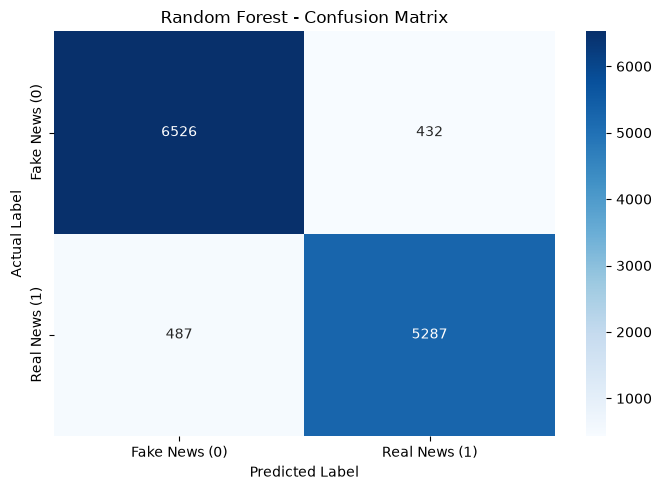

In [51]:
cm_rf = confusion_matrix(y_test, y_pred_rf)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_rf,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Fake News (0)", "Real News (1)"],
    yticklabels=["Fake News (0)", "Real News (1)"]
)

plt.title("Random Forest - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

## Comparative Evaluation of Classification Models

Four machine learning algorithms were evaluated using
the same TF-IDF features and test dataset.

| Algorithm | Accuracy | Precision | Recall | F1-score |
|---|---:|---:|---:|---:|
| Logistic Regression | 95.98% | 95.44% | 95.70% | 95.57% |
| Multinomial Naive Bayes | 86.98% | 83.86% | 88.28% | 86.01% |
| Linear SVM | 97.17% | 96.74% | 97.04% | 96.89% |
| Random Forest | 92.78% | 92.45% | 91.57% | 92.00% |

### Observations

- Linear SVM achieved the highest accuracy and F1-score.
- Logistic Regression also demonstrated strong classification performance.
- Random Forest performed better than Multinomial Naive Bayes.
- Multinomial Naive Bayes showed comparatively lower performance.

### Conclusion

Linear SVM is the leading model in the current experiment,
achieving 97.17% accuracy and 96.89% F1-score.

It will be considered the primary candidate for further
optimization and validation.

Further testing is required before final model selection.

### Phase 7 – Model Optimization and Validation

In [52]:
# Compare C values 

from sklearn.model_selection import train_test_split
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, f1_score
import pandas as pd

# Create validation split from training data
X_train_sub, X_val, y_train_sub, y_val = train_test_split(
    X_train_tfidf,
    y_train,
    test_size=0.15,
    random_state=42,
    stratify=y_train
)

results = []

# Test different C values
for c_value in [0.1, 1.0, 10.0]:

    model = LinearSVC(
        C=c_value,
        max_iter=3000,
        random_state=42
    )

    model.fit(X_train_sub, y_train_sub)

    val_predictions = model.predict(X_val)

    results.append({
        "C": c_value,
        "Accuracy": accuracy_score(y_val, val_predictions),
        "F1 Score": f1_score(y_val, val_predictions)
    })

# Display comparison
tuning_results = pd.DataFrame(results)

print("LINEAR SVM HYPERPARAMETER COMPARISON")
print(tuning_results.round(4).to_string(index=False))

LINEAR SVM HYPERPARAMETER COMPARISON
   C  Accuracy  F1 Score
 0.1    0.9671    0.9637
 1.0    0.9751    0.9725
10.0    0.9724    0.9694


In [53]:
# Retrain the selected model 

from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Initialize best Linear SVM
best_svm_model = LinearSVC(
    C=1.0,
    max_iter=3000,
    random_state=42
)

# Train on complete training data
best_svm_model.fit(X_train_tfidf, y_train)

# Predict unseen test data
y_pred_best_svm = best_svm_model.predict(X_test_tfidf)

# Evaluate
print("OPTIMIZED LINEAR SVM RESULTS")
print("-" * 40)

print("Accuracy :", round(accuracy_score(y_test, y_pred_best_svm), 4))
print("Precision:", round(precision_score(y_test, y_pred_best_svm), 4))
print("Recall   :", round(recall_score(y_test, y_pred_best_svm), 4))
print("F1 Score :", round(f1_score(y_test, y_pred_best_svm), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_best_svm))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_best_svm))

OPTIMIZED LINEAR SVM RESULTS
----------------------------------------
Accuracy : 0.9717
Precision: 0.9674
Recall   : 0.9704
F1 Score : 0.9689

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.97      0.97      6958
           1       0.97      0.97      0.97      5774

    accuracy                           0.97     12732
   macro avg       0.97      0.97      0.97     12732
weighted avg       0.97      0.97      0.97     12732


Confusion Matrix:
[[6769  189]
 [ 171 5603]]


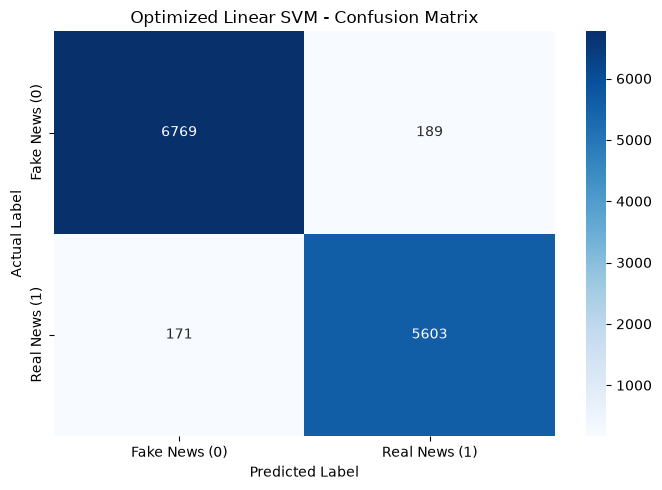

In [54]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred_best_svm)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Fake News (0)", "Real News (1)"],
    yticklabels=["Fake News (0)", "Real News (1)"]
)

plt.title("Optimized Linear SVM - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

### Optimized Linear SVM – Evaluation

- Best C value: 1.0
- Test Accuracy: 97.17%
- Precision: 96.74% (Real News)
- Recall: 97.04% (Real News)
- F1-score: 96.89% (Real News)

**Conclusion:**

Linear SVM with C=1.0 achieved 97.17% test accuracy.
The model demonstrated strong and balanced classification
performance across both target classes.

Hyperparameter tuning confirmed C=1.0 as the best
configuration among the tested values.

The optimized model is selected as our current leading
candidate for further validation.

In [55]:
# Error Analysis 

import pandas as pd

# Create error analysis DataFrame
error_df = pd.DataFrame({
    "Actual_Label": y_test.values,
    "Predicted_Label": y_pred_best_svm,
    "Text": X_test.values
})

# Select incorrectly classified records
misclassified_df = error_df[
    error_df["Actual_Label"] != error_df["Predicted_Label"]
].copy()

# Add error category
misclassified_df["Error_Type"] = misclassified_df.apply(
    lambda row: (
        "False Positive"
        if row["Actual_Label"] == 0
        else "False Negative"
    ),
    axis=1
)

print("Total Misclassified:", len(misclassified_df))

print("\nError Distribution:")
print(misclassified_df["Error_Type"].value_counts())

Total Misclassified: 360

Error Distribution:
Error_Type
False Positive    189
False Negative    171
Name: count, dtype: int64


In [57]:
# Display 5 False Positives
print("FALSE POSITIVES")
print("=" * 80)

for i, row in misclassified_df[
    misclassified_df["Error_Type"] == "False Positive"
].head(5).iterrows():

    print("\nArticle:", row["Text"][:500])
    print("Actual:", row["Actual_Label"])
    print("Predicted:", row["Predicted_Label"])

FALSE POSITIVES

Article: when eve and eve bit the apple the new york times when you are raised to be a good christian girl you don t just go to church you date the church church is the significant other with whom you spend weekends and evenings the boyfriend whose friends become your friends the girlfriend with whom you share all your dreams i was a really good christian girl so i didn t just date the church i married it after graduating from a midwestern college whose motto is for christ and his kingdom i moved to new 
Actual: 0
Predicted: 1

Article: clinton camp in damage control mode over top secret emails the latest revelations on hillary s emails again point to one thing she is disqualified from being president
Actual: 0
Predicted: 1

Article: nevada politics expert trump is dead in the state when national media outlets need to know what s going on in nevada politics they often turn to las vegas based journalist jon ralston who s developed a strong track record of calling electi

In [58]:

# Display 5 False Negatives
print("\nFALSE NEGATIVES")
print("=" * 80)

for i, row in misclassified_df[
    misclassified_df["Error_Type"] == "False Negative"
].head(5).iterrows():

    print("\nArticle:", row["Text"][:500])
    print("Actual:", row["Actual_Label"])
    print("Predicted:", row["Predicted_Label"])


FALSE NEGATIVES

Article: north korea threatens sacred nuclear war against israel if this country continue supporting isis email north korea s foreign ministry slammed the shamelessness of israel on friday calling the jewish state a rogue group that poses a nuclear threat and commits terrorist attack s against neighboring countries on friday the korean central news agency released a statement attributed to north korea s foreign ministry that responded to comments israeli prime minister benjamin netanyahu made last week t
Actual: 1
Predicted: 0

Article: breaking federal judge stops obamacare transgender abortion related protections o connor found that the plaintiffs had standing to bring the lawsuit because they have presented concrete evidence to support their fears that they will be subject to enforcement under the rule washington a federal judge in texas on saturday issued a nationwide injunction halting enforcement of obama administration protections for transgender and abortion r

### Error Analysis – Linear SVM

Total Misclassified Records: 360

- False Positives: 189
- False Negatives: 171

### False Positive Observations

Some Fake News articles use conventional reporting,
political analysis and editorial writing styles.

These linguistic patterns can resemble genuine news
articles, causing incorrect Real News predictions.

### False Negative Observations

Some Real News articles contain sensational wording,
emotionally charged language and politically controversial
topics.

These patterns may resemble Fake News examples learned
during training.

### Conclusion

The error analysis indicates that overlapping vocabulary,
writing styles and political terminology contribute to
misclassification.

TF-IDF captures statistical word patterns but does not
understand factual context or verify news authenticity.

Contextual NLP models may help address some of these
limitations in future experiments.

In [59]:
# Inspect prediction confidence 

# Get decision scores from optimized Linear SVM
decision_scores = best_svm_model.decision_function(X_test_tfidf)

# Create prediction analysis DataFrame
confidence_df = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred_best_svm,
    "Decision_Score": decision_scores,
    "Correct": y_test.values == y_pred_best_svm
})

print("Prediction Confidence Analysis")

print("\nCorrect Predictions:")
print(
    confidence_df[confidence_df["Correct"]]["Decision_Score"]
    .describe().round(4)
)

print("\nIncorrect Predictions:")
print(
    confidence_df[~confidence_df["Correct"]]["Decision_Score"]
    .describe().round(4)
)

Prediction Confidence Analysis

Correct Predictions:
count    12372.0000
mean        -0.0974
std          1.4543
min         -3.2501
25%         -1.3851
50%         -0.5814
75%          1.2432
max          4.2083
Name: Decision_Score, dtype: float64

Incorrect Predictions:
count    360.0000
mean      -0.0001
std        0.3846
min       -1.3542
25%       -0.2203
50%        0.0207
75%        0.2215
max        1.4267
Name: Decision_Score, dtype: float64


### Decision Score Analysis – Conclusion

- Correct predictions generally have decision scores farther from zero, indicating stronger separation from the decision boundary.
- Incorrect predictions have a median decision score close to zero (0.0207), suggesting that many errors occur on ambiguous samples.
- The Linear SVM can still make incorrect predictions with relatively large decision scores, so decision scores should not be interpreted as probabilities.
- This analysis helps identify uncertain predictions and provides insight into the model's classification behaviour.

**Conclusion:** The Linear SVM performs well overall, but articles with ambiguous language or overlapping writing patterns remain challenging to classify.

In [60]:
# Cross-Validation 

from sklearn.model_selection import StratifiedKFold, cross_validate

svm_cv = LinearSVC(
    C=1.0,
    max_iter=3000,
    random_state=42
)

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1"
}

cv_results = cross_validate(
    svm_cv,
    X_train_tfidf,
    y_train,
    cv=skf,
    scoring=scoring,
    n_jobs=-1
)

print("5-Fold Cross-Validation Results")

for metric in scoring:
    scores = cv_results[f"test_{metric}"]
    print(f"\n{metric.capitalize()}:")
    print("Fold Scores:", scores.round(4))
    print("Mean:", round(scores.mean(), 4))
    print("Standard Deviation:", round(scores.std(), 4))

5-Fold Cross-Validation Results

Accuracy:
Fold Scores: [0.9732 0.9754 0.973  0.9723 0.9684]
Mean: 0.9725
Standard Deviation: 0.0023

Precision:
Fold Scores: [0.971  0.9703 0.9695 0.9699 0.9615]
Mean: 0.9684
Standard Deviation: 0.0035

Recall:
Fold Scores: [0.9699 0.9755 0.971  0.969  0.969 ]
Mean: 0.9709
Standard Deviation: 0.0024

F1:
Fold Scores: [0.9704 0.9729 0.9703 0.9695 0.9653]
Mean: 0.9697
Standard Deviation: 0.0025


### 5-Fold Cross-Validation – Conclusion

- Applied Stratified 5-Fold Cross-Validation to evaluate the consistency of the Linear SVM model.
- Achieved an average accuracy of 97.25% and an average F1-score of 96.97%.
- Precision and recall achieved 96.84% and 97.09%, respectively.
- The standard deviations across all metrics were very low, indicating consistent performance across the five folds.
- The held-out test dataset was not used during cross-validation.

**Conclusion:** The Linear SVM demonstrates strong and consistent classification performance across different training and validation folds. It remains our leading traditional machine learning model.

In [61]:
# ROC-AUC Evaluation 

from sklearn.metrics import roc_auc_score, roc_curve
import matplotlib.pyplot as plt

# Generate decision scores
y_scores = best_svm_model.decision_function(X_test_tfidf)

# Calculate ROC-AUC
roc_auc = roc_auc_score(y_test, y_scores)

print("Linear SVM ROC-AUC Score:", round(roc_auc, 4))

Linear SVM ROC-AUC Score: 0.9965


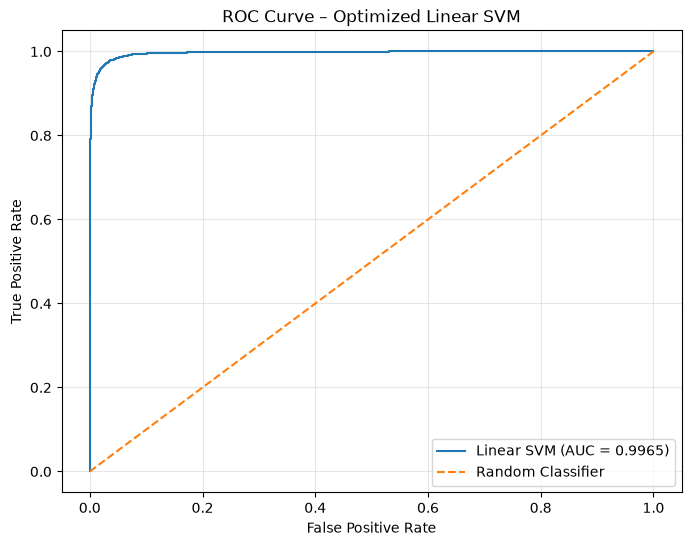

In [62]:
# Calculate ROC curve values
fpr, tpr, thresholds = roc_curve(y_test, y_scores)

# Plot ROC curve
plt.figure(figsize=(8, 6))

plt.plot(
    fpr, tpr,
    label=f"Linear SVM (AUC = {roc_auc:.4f})"
)

# Random classifier reference line
plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve – Optimized Linear SVM")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### ROC-AUC Evaluation – Conclusion

- Evaluated the optimized Linear SVM using the ROC-AUC metric.
- Achieved an ROC-AUC score of 0.9965 (99.65%) on the test dataset.
- The ROC curve is positioned close to the top-left corner, indicating excellent discrimination between Fake News and Real News.
- The model performs significantly better than the random classifier baseline.

**Conclusion:** The optimized Linear SVM demonstrates excellent class discrimination on the held-out test dataset. However, further validation on independent news sources is necessary before considering it reliable for real-world fake news detection.

# Final Conclusion

The Fake News Detection project was successfully developed using Natural Language Processing (NLP) and supervised Machine Learning techniques to classify news articles into Fake News and Real News categories.

The project followed an end-to-end machine learning workflow, including problem understanding, exploratory data analysis (EDA), data cleaning, text preprocessing, feature extraction using TF-IDF, model development, evaluation, hyperparameter tuning, and error analysis.

Four machine learning algorithms were implemented and evaluated:

- Logistic Regression
- Multinomial Naive Bayes
- Linear Support Vector Machine (Linear SVM)
- Random Forest Classifier

Among the evaluated models, **Linear SVM achieved the best overall performance** on the held-out test dataset.

### Best Model Performance

| Evaluation Metric | Score |
|---|---:|
| Accuracy | 97.17% |
| Precision | 96.74% |
| Recall | 97.04% |
| F1-Score | 96.89% |

The Linear SVM model correctly classified 12,372 out of 12,732 test samples, with 360 misclassifications.

Hyperparameter tuning was performed using different C values, and C = 1.0 produced the best validation performance among the tested configurations.

Error analysis helped identify patterns in incorrectly classified articles, highlighting the challenges of distinguishing fake and real news based solely on textual characteristics.

### Overall Outcome

The project demonstrates that traditional machine learning algorithms combined with TF-IDF feature extraction can achieve strong classification performance on the WELFake dataset.

The developed model can serve as a preliminary news classification system to identify potentially misleading content based on learned textual patterns.

However, the model does not independently verify facts, sources, or the authenticity of news claims. Its predictions should therefore be treated as indicators rather than definitive judgments.

Future improvements may include Word2Vec embeddings, LSTM, BiLSTM, Transformer architectures, and BERT-based classification to explore deeper semantic and contextual understanding of news articles.

# Business Recommendations

Based on the results of the Fake News Detection project, the following recommendations can help organizations, digital media platforms, and news monitoring systems improve their content screening processes.

### 1. Automated News Screening

- Integrate the trained Linear SVM model into a news monitoring platform.
- Automatically analyze incoming news headlines and article content.
- Flag articles predicted as potentially fake for additional review.
- Reduce the manual effort involved in preliminary content screening.

### 2. Human-in-the-Loop Verification

- Do not automatically remove or block articles based only on model predictions.
- Send suspicious articles to professional fact-checkers or content moderators.
- Combine machine learning predictions with reliable external evidence and source verification.
- Allow human reviewers to make the final decision.

### 3. Real-Time Content Monitoring

- Develop an API using FastAPI to expose the trained model.
- Integrate the API with a web-based application or content monitoring dashboard.
- Enable users to submit news articles and receive classification results.
- Monitor prediction trends and model performance over time.

### 4. Continuous Model Improvement

- Regularly collect newly published and verified news articles.
- Update the training dataset with diverse topics, publishers, and writing styles.
- Monitor false positives and false negatives.
- Retrain and evaluate the model periodically to address changing language patterns and misinformation techniques.

### 5. Advanced NLP Integration

- Explore Word2Vec, LSTM, and BiLSTM for improved text representation and sequential learning.
- Experiment with Transformer-based models such as BERT.
- Compare advanced NLP models against the current TF-IDF and Linear SVM baseline.
- Evaluate improvements using Precision, Recall, F1-Score, and confusion matrices.

### 6. Responsible Deployment

- Clearly communicate that predictions are based on learned patterns in historical data.
- Avoid presenting model predictions as verified facts.
- Evaluate the model across different topics, publishers, and time periods before production deployment.
- Monitor potential dataset bias and incorrect classifications.

### Expected Business Benefits

- Faster preliminary news screening.
- Reduced manual content review workload.
- Early identification of potentially misleading articles.
- Better support for content moderation teams.
- A scalable foundation for developing intelligent news monitoring applications.

# Limitations

1. The model learns patterns from the WELFake dataset and may not generalize equally well to all news sources or future events.
2. TF-IDF captures word and phrase importance but does not fully understand semantic meaning or contextual relationships.
3. The model may misclassify articles containing unusual writing styles, political language, sensational expressions, or unfamiliar topics.
4. Dataset quality, labeling accuracy, source distribution, and potential biases can influence model performance.
5. The system classifies textual patterns; it does not perform independent fact-checking or verify the authenticity of news claims.

Therefore, the model should be used as a decision-support tool alongside human verification rather than as a standalone fact-checking solution.